# Figure 2 — CDK9 and CDK7 resistance

Reads only `data/processed/` and `data/reference/`. Nothing here recomputes a
screen statistic; if a number looks wrong the fix belongs upstream.

| panel | content | from | status |
|---|---|---|---|
| a | Lollipop, KI-CDK9d-32 1,000 nM, subpool 1 | `09_analysis_and_viz/lollipop_plots_canonical.ipynb cell 15` | **figure** |
| b | CDK9 top variants, per-replicate LFC | `09_analysis_and_viz/logo_plots.ipynb cells 60-62` | **figure** |
| c | ChimeraX renders for figure 2c (2 images), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| d | MTT dose-response, CDK9 L156F | `source_data/04_MTT_data/FACS_dose_response_2024_8_22.ipynb cells 126-127` | **figure** |
| f | Competition-assay panel 2f | `cdkbe.source_data.competition_assays` | **figure** |
| h | Lollipop, SY-5609 10 nM, subpool 1 | `09_analysis_and_viz/lollipop_plots_canonical.ipynb cell 15` | **figure** |
| i | CDK7 SY-5609 resistance hits | `09_analysis_and_viz/CDK7_SY5609_hits.ipynb cells 8/10/14` | **figure** |
| j | ChimeraX render for figure 2j (1 image), with the residues marked | `cdkbe.source_data.structures` | **figure** |
| k | MTT dose-response, CDK7 L18F | `source_data/04_MTT_data/FACS_dose_response_2024_8_22.ipynb cell 130` | **figure** |
| m | Xenograft tumour volume fold change | `11_in_vivo_analysis/invivo_xenograft_CDK9_CDK7_combined.ipynb cell 5` | **figure** |
| n | Xenograft Ki67 | `11_in_vivo_analysis/invivo_xenograft_CDK9_CDK7_combined.ipynb cell 7` | **figure** |

**figure** — this notebook regenerates both the source data and the panel.
**source data** — the table regenerates and is checked by `tests/`; the
plotting is still in the original notebook named above.
**not ported** — the plotting is not in this repository yet.
See `docs/COVERAGE.md` for the status of every panel.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(next(p for p in Path.cwd().resolve().parents
                            if (p / "src" / "cdkbe").is_dir()) / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cdkbe import paths, io, editing, lfc, plotting
from cdkbe.source_data import PANELS

plotting.use_style()
paths.ensure(paths.FIG_MAIN)

## Source data

The frames these panels plot.

In [2]:
for key in ["2a", "2b", "2c", "2d", "2f", "2h", "2i", "2j", "2k", "2m", "2n"]:
    result = PANELS[key]()
    frames = result if isinstance(result, dict) else {"": result}
    for name, df in frames.items():
        label = f"{key}/{name}" if name else key
        print(f"{label:<28} {len(df):>8,} rows x {len(df.columns)} cols")

2a                              3,716 rows x 11 cols


2b/hits                            10 rows x 15 cols
2b/per_replicate_LFC              150 rows x 6 cols
2c                                 12 rows x 12 cols
2d                                 96 rows x 7 cols
2f                                  8 rows x 9 cols


2h                              3,697 rows x 11 cols
2i/hits                             9 rows x 11 cols
2i/per_replicate_LFC               54 rows x 6 cols
2j                                  9 rows x 12 cols
2k                                 48 rows x 7 cols
2m                                 40 rows x 10 cols


2n                                 40 rows x 11 cols


## Panels

Each panel below is drawn from `data/processed/` and rendered inline, and also
written to `figures/main/`. The numbers printed on the in vivo panels are
checked against the manuscript in `tests/test_invivo_figures.py`.

In [3]:
from matplotlib.figure import Figure

from cdkbe.source_data import DRAWN
from cdkbe.source_data import invivo_figures as ivf

# Drawing functions predate this notebook and return four different shapes: a
# bare figure, (figure, source rows), a dict of either keyed by gene or by
# sub-panel, or -- for the in vivo cohorts -- a list of (figure, stats) pairs.
# `show` takes them all rather than each cell knowing which it is getting.
DRAW = {k: ("invivo" if k in ivf.FIGURES else "screen", v)
        for k, v in DRAWN.items()}


def show(fig, note=None):
    if note:
        print(note)
    display(fig)
    plt.close(fig)


def describe(obj):
    if isinstance(obj, dict):
        return ", ".join(f"{e}: {len(g):,} guides" for e, g in obj.items())
    return f"{len(obj):,} rows"


def draw(key):
    """Draw one panel, show it, and report what it is made of."""
    kind, fn = DRAW[key]
    result = fn(outdir=paths.FIG_MAIN)
    if kind == "invivo":
        for fig, stats in result:
            cols = [c for c in ["Cohort", "comparison", "group",
                                "n_WT", "n_mutant", "p_shown"] if c in stats.columns]
            display(stats[cols])
            show(fig)
        return
    if isinstance(result, Figure):
        show(result)
        return
    if isinstance(result, dict):              # one figure per gene or sub-panel
        for name, v in result.items():
            if isinstance(v, Figure):
                show(v, f"{key} {name}")
            else:
                fig, sub = v
                show(fig, f"{key} {name}: {describe(sub)}")
        return
    fig, obj = result
    if not isinstance(fig, Figure):           # a ChimeraX panel: rendered images
        print(describe(obj))
        display(fig)                          # tiled preview; see structures.Renders
        return
    show(fig, describe(obj))

### 2a — Lollipop, KI-CDK9d-32 1,000 nM, subpool 1

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


CBE: 1,807 guides, ABE: 1,909 guides


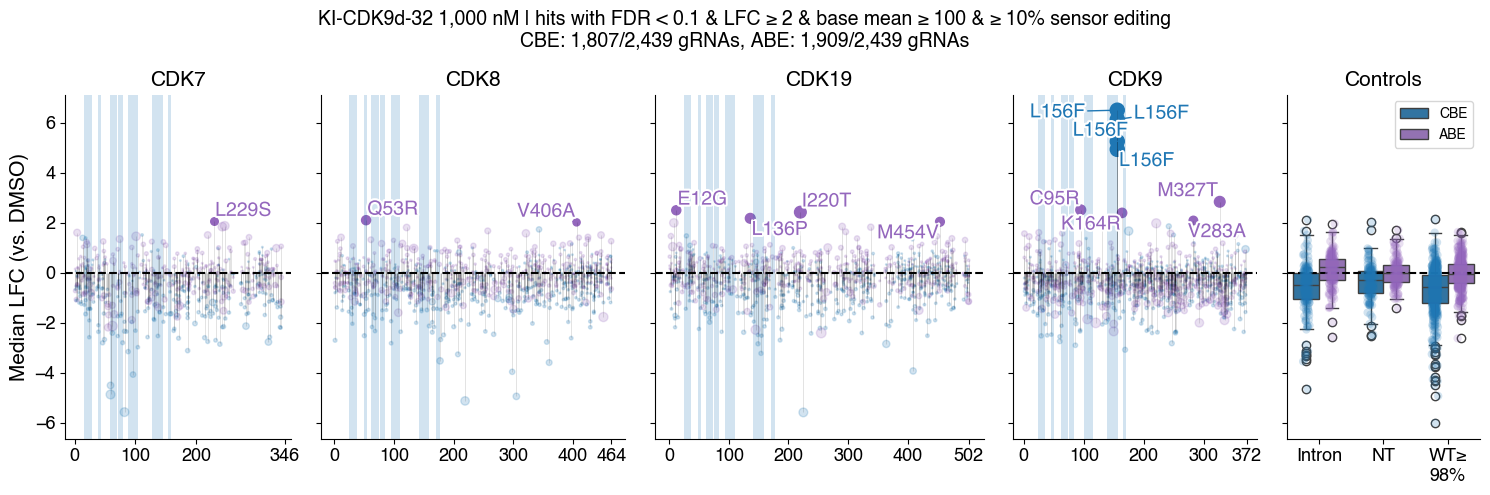

In [4]:
draw("2a")

### 2b — CDK9 top variants, per-replicate LFC

Matplotlib is building the font cache; this may take a moment.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


10 rows


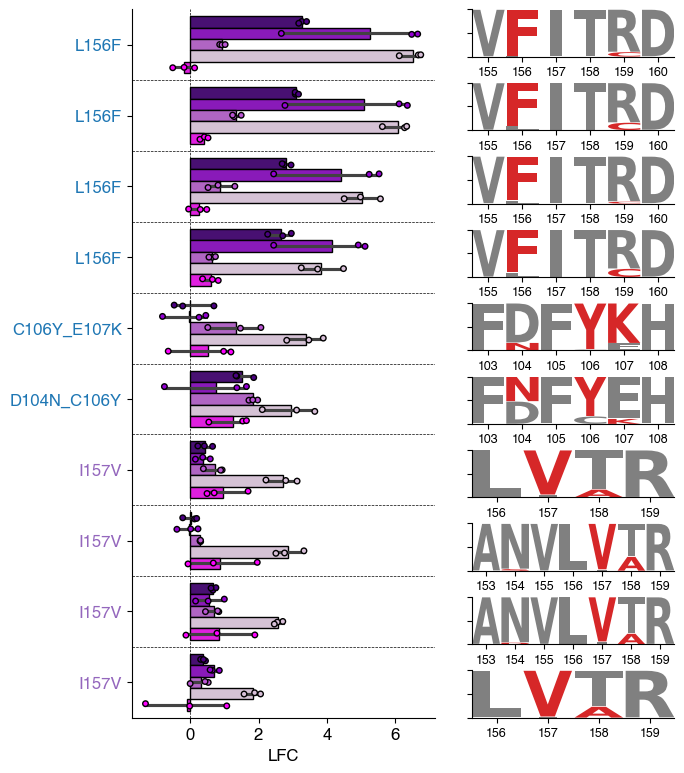

In [5]:
draw("2b")

### 2c — ChimeraX renders for figure 2c (2 images), with the residues marked

12 rows


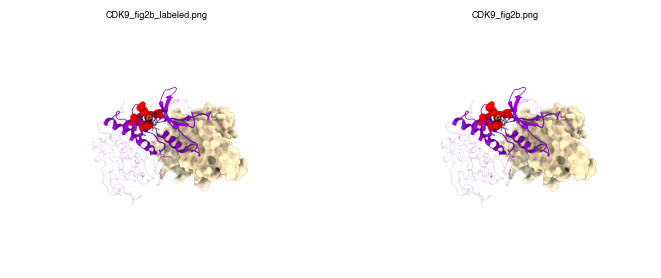

In [6]:
draw("2c")

### 2d — MTT dose-response, CDK9 L156F

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


2d KI-CDK9d-32: 2 rows


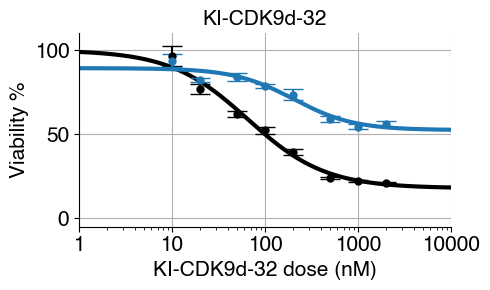

2d KB-0742: 2 rows


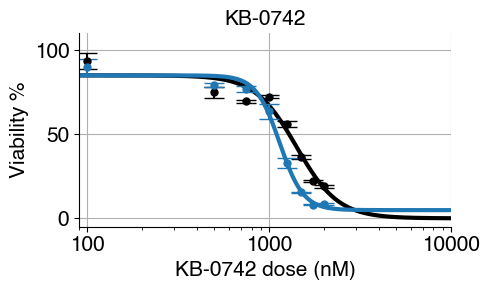

In [7]:
draw("2d")

### 2f — Competition-assay panel 2f

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


8 rows


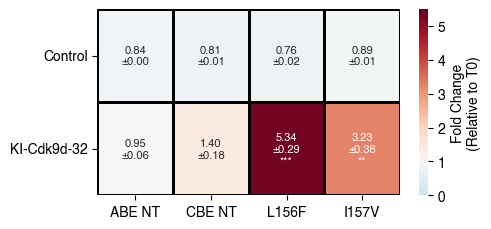

In [8]:
draw("2f")

### 2h — Lollipop, SY-5609 10 nM, subpool 1

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


CBE: 1,803 guides, ABE: 1,894 guides


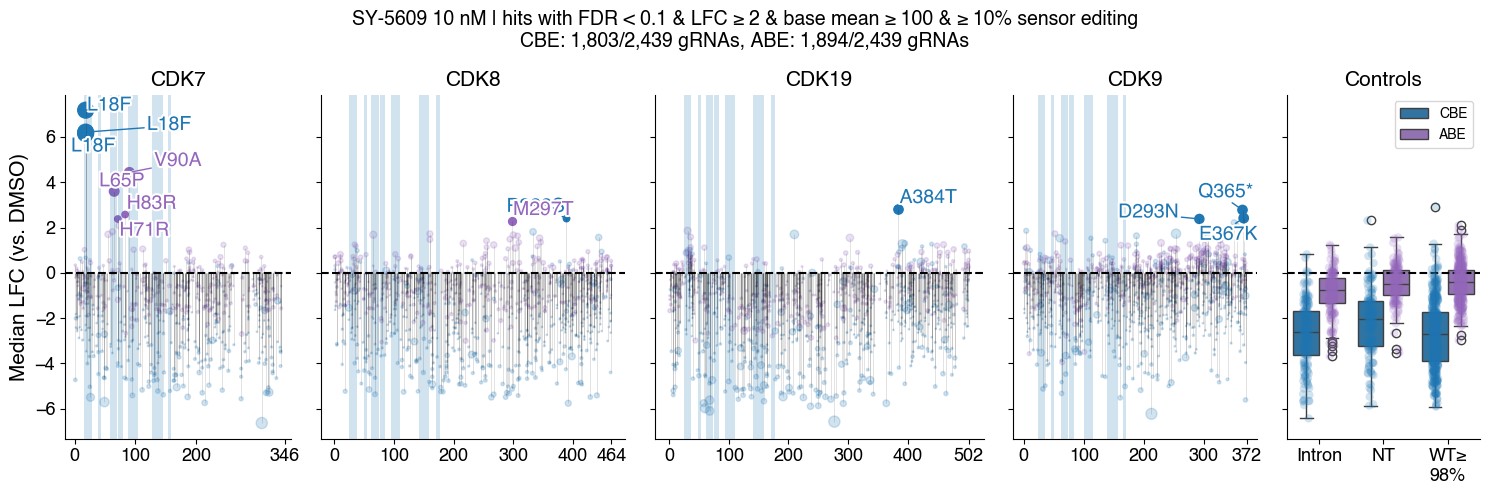

In [9]:
draw("2h")

### 2i — CDK7 SY-5609 resistance hits

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


9 rows


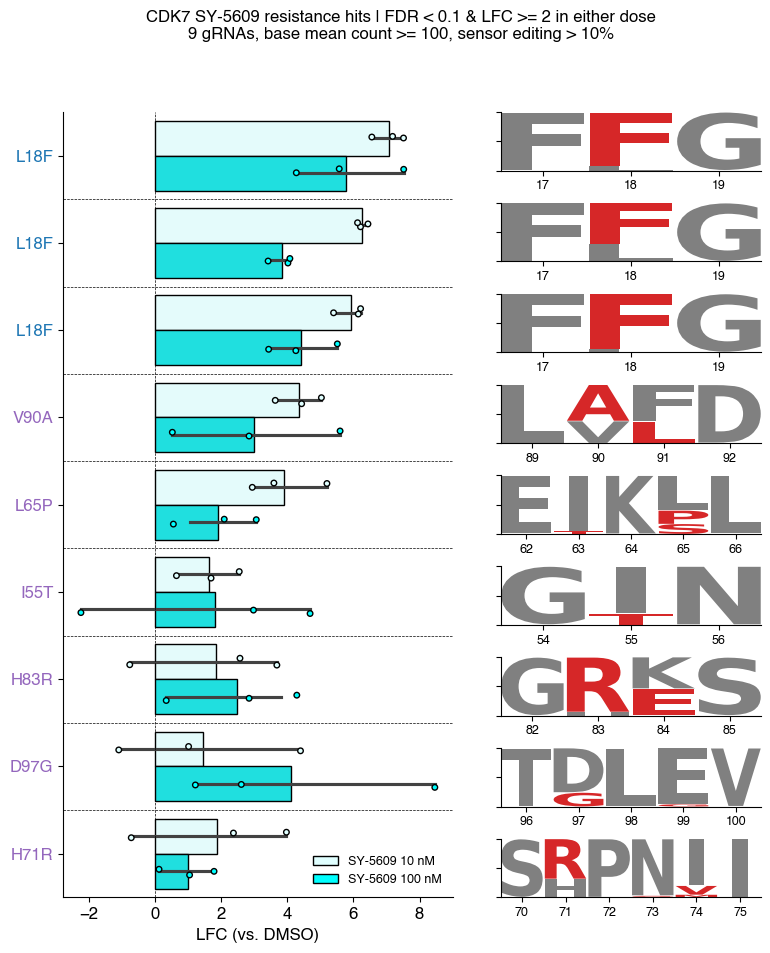

In [10]:
draw("2i")

### 2j — ChimeraX render for figure 2j (1 image), with the residues marked

9 rows


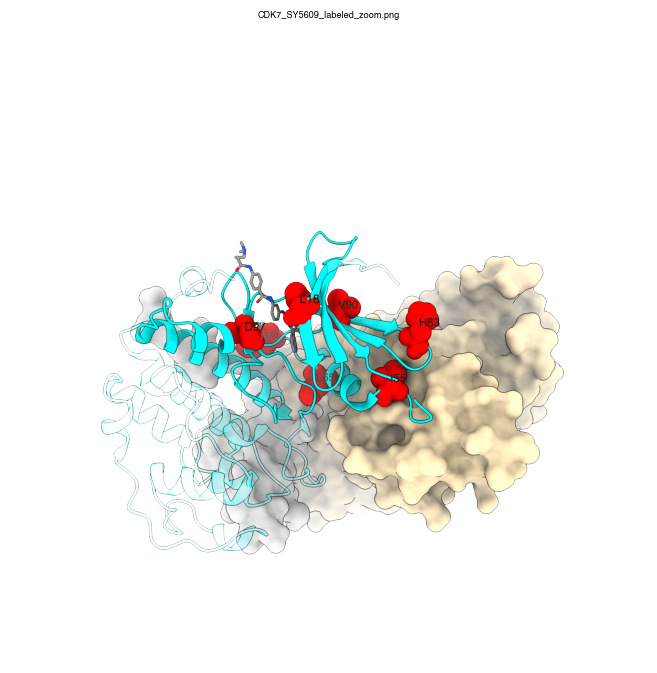

In [11]:
draw("2j")

### 2k — MTT dose-response, CDK7 L18F

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


2k SY-5609: 2 rows


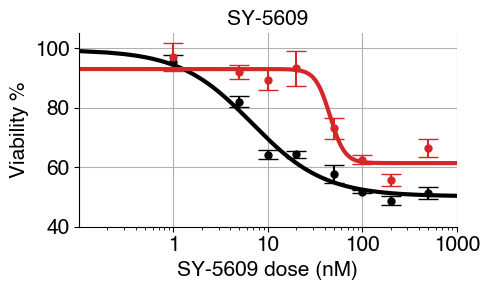

In [12]:
draw("2k")

### 2m — Xenograft tumour volume fold change

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


,Cohort,n_WT,n_mutant,p_shown
0,CDK9 I157V,5,5,0.176120
1,CDK9 I157V,3,4,0.044876
2,CDK9 I157V,5,3,0.452201
3,CDK9 I157V,5,4,0.677675


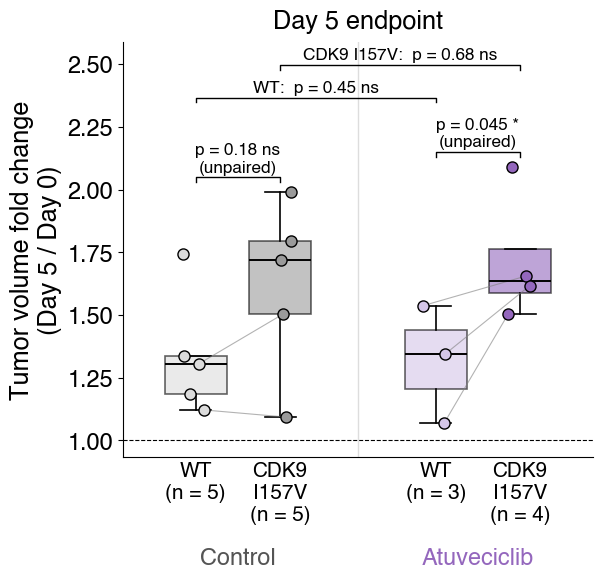

,Cohort,n_WT,n_mutant,p_shown
0,CDK7 L18F,5,5,0.364001
1,CDK7 L18F,7,6,0.015569
2,CDK7 L18F,5,7,0.003974
3,CDK7 L18F,5,6,0.297533


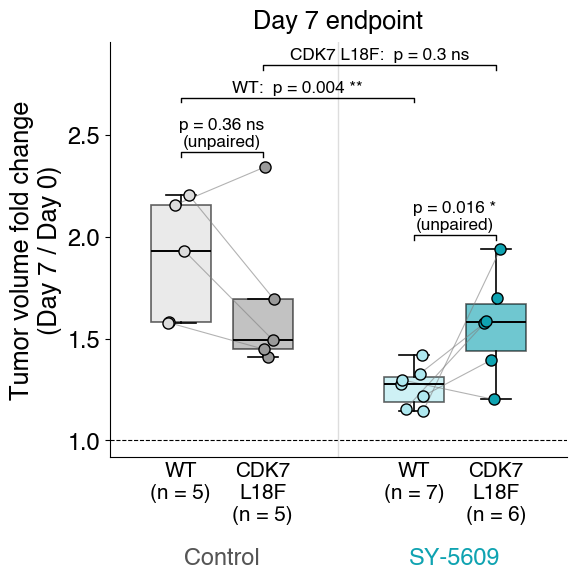

In [13]:
draw("2m")

### 2n — Xenograft Ki67

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Zapf NOT subset; don't know how to subset; dropped


feat NOT subset; don't know how to subset; dropped


morx NOT subset; don't know how to subset; dropped


,Cohort,n_WT,n_mutant,p_shown
0,CDK9 I157V,5,5,0.917005
1,CDK9 I157V,3,4,0.048317
2,CDK9 I157V,5,3,0.016383
3,CDK9 I157V,5,4,0.748429


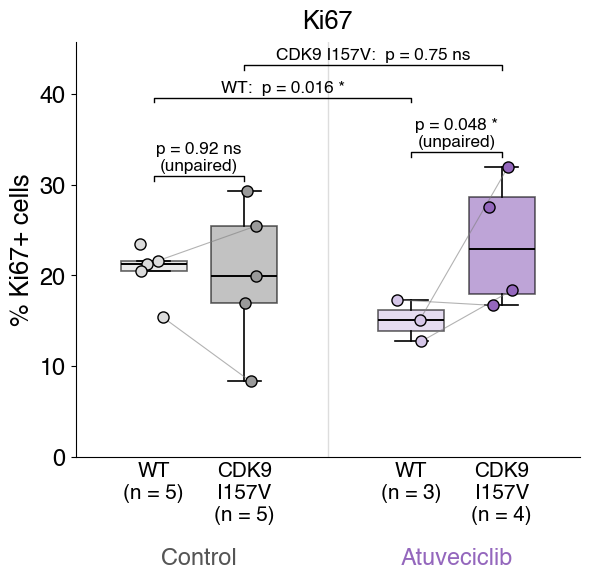

,Cohort,n_WT,n_mutant,p_shown
0,CDK7 L18F,5,5,0.012350
1,CDK7 L18F,7,6,0.837407
2,CDK7 L18F,5,7,0.008000
3,CDK7 L18F,5,6,0.729559


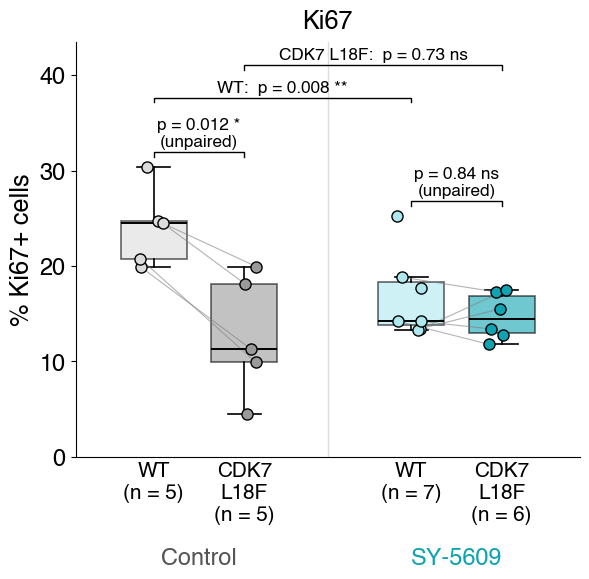

In [14]:
draw("2n")